# Practical Exercise 3 (Part 2): Uniform Cost Search for the Trailer
**ICS 3202 Artificial Intelligence** | Nairobi to Kisumu

## Group members
| Student number | Name |
|---|---|
| 189984 | Muriuki Alvin Murithi |
| 192576 | Sebudde Jeremy Mwesigwa |
| 189588 | Mutungi Travis Njenga |

**Repository:** [cypher-30/PS-Agents](https://github.com/cypher-30/PS-Agents)

## What this notebook does
In Part 1 we turned the highway network into a graph. Each **town** is a node and each **road between two towns** is a link. The link cost is the driving distance in km from Google Maps.

In Part 2 (this notebook) we make the trailer search that graph with **Uniform Cost Search (UCS)**, the way we did it in class:

1. Keep a **frontier** (a waiting list) of towns we have reached but not yet visited, each with the cost of the cheapest route found so far.
2. Always **expand the cheapest town** on the frontier.
3. If that town is the goal, **stop**. Because we always take the cheapest one first, the first time we pull Kisumu off the frontier its route is the cheapest possible.
4. Otherwise add its neighbours to the frontier. If a neighbour is already there with a higher cost, keep the cheaper route.

At the end we print the **optimal path and its cost**.

## Step 1: The graph from Part 1
These are the 10 road links and distances (km) we measured on Google Maps on 16 October 2026, using the route Google recommends first. Every road is two-way, so each link goes in both directions.

In [1]:
# Road distances (km) between neighbouring towns, from Part 1 (Google Maps, 16 Oct 2026)
roads = [
    ("Nairobi",  "Naivasha", 91.0),
    ("Naivasha", "Nakuru",   70.5),
    ("Nairobi",  "Thika",    45.1),
    ("Thika",    "Nyeri",   113.0),
    ("Nyeri",    "Nakuru",  167.0),
    ("Nakuru",   "Kericho", 107.0),
    ("Kericho",  "Kisumu",   84.0),
    ("Nakuru",   "Eldoret", 156.0),
    ("Eldoret",  "Kakamega",107.0),
    ("Kakamega", "Kisumu",   53.4),
]

# Turn the list into a dictionary: graph[town] = {neighbour: distance, ...}
graph = {}
for a, b, km in roads:
    graph.setdefault(a, {})[b] = km   # a -> b
    graph.setdefault(b, {})[a] = km   # b -> a (two-way road)

start, goal = "Nairobi", "Kisumu"

for town, links in graph.items():
    print(f"{town:9s} -> {links}")

Nairobi   -> {'Naivasha': 91.0, 'Thika': 45.1}
Naivasha  -> {'Nairobi': 91.0, 'Nakuru': 70.5}
Nakuru    -> {'Naivasha': 70.5, 'Nyeri': 167.0, 'Kericho': 107.0, 'Eldoret': 156.0}
Thika     -> {'Nairobi': 45.1, 'Nyeri': 113.0}
Nyeri     -> {'Thika': 113.0, 'Nakuru': 167.0}
Kericho   -> {'Nakuru': 107.0, 'Kisumu': 84.0}
Kisumu    -> {'Kericho': 84.0, 'Kakamega': 53.4}
Eldoret   -> {'Nakuru': 156.0, 'Kakamega': 107.0}
Kakamega  -> {'Eldoret': 107.0, 'Kisumu': 53.4}


## Step 2: Picture of the graph
Each oval is a town, each line is a road and the number on it is the distance in km. Town positions roughly follow the real map (west is left, north is up).

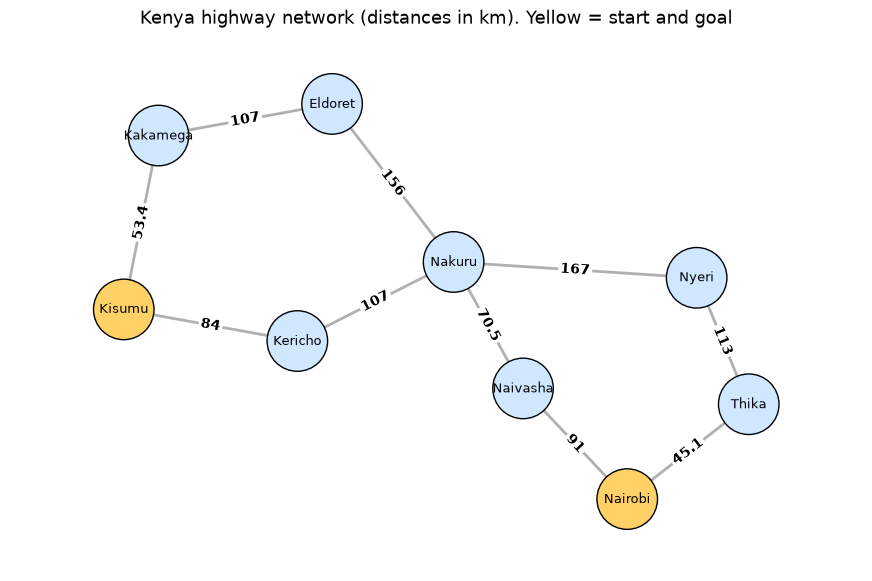

In [2]:
import matplotlib.pyplot as plt
import networkx as nx

# Hand-placed positions: west is left, north is up (spaced out so labels stay readable)
pos = {
    "Nairobi": (36.9, -1.5), "Thika": (37.6, -0.9), "Nyeri": (37.3, -0.1),
    "Naivasha": (36.3, -0.8), "Nakuru": (35.9, 0.0), "Kericho": (35.0, -0.5),
    "Kisumu": (34.0, -0.3), "Kakamega": (34.2, 0.8), "Eldoret": (35.2, 1.0),
}

G = nx.Graph()
for a, b, km in roads:
    G.add_edge(a, b, km=km)

def draw_graph(highlight_path=None, title=""):
    fig, ax = plt.subplots(figsize=(11, 7))
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#b0b0b0", width=2)
    if highlight_path:
        edges = list(zip(highlight_path, highlight_path[1:]))
        nx.draw_networkx_edges(G, pos, ax=ax, edgelist=edges, edge_color="#e63946", width=5)
    colours = ["#ffd166" if n in (start, goal) else "#cfe8ff" for n in G.nodes]
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colours, node_size=1900, edgecolors="black")
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=9)
    nx.draw_networkx_edge_labels(G, pos, ax=ax, edge_labels={(a, b): f"{km:g}" for a, b, km in roads},
                                 font_size=10, font_weight="bold", label_pos=0.5,
                                 bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
    ax.set_title(title, fontsize=13)
    ax.margins(0.12)
    ax.axis("off")
    plt.show()

draw_graph(title="Kenya highway network (distances in km). Yellow = start and goal")

## Step 3: The Uniform Cost Search code
How the code lines up with the steps above:

* `frontier` is a **priority queue** (Python's `heapq`). It always gives back the entry with the **smallest cost** first. That is the "expand the cheapest town" rule.
* `best_cost[town]` remembers the cheapest cost found so far to each town. When we find a cheaper way to a town we replace it, and the old, more expensive entry is ignored later.
* `explored` is the set of towns already expanded. We never expand a town twice.
* The **goal test happens when a town is taken off the frontier**, not when it is first added. This is what guarantees the first route to Kisumu we expand is the cheapest.
* `trace` records every step so we can print a table of what happened, like in class.

In [3]:
import heapq

def uniform_cost_search(graph, start, goal):
    """Uniform Cost Search. Returns (path, cost, trace)."""
    # Frontier entries look like (cost so far, town, path taken to get there)
    frontier = [(0.0, start, [start])]
    best_cost = {start: 0.0}   # cheapest known cost to each town
    explored = set()           # towns we have already expanded
    trace = []                 # one row per expansion, for the table later

    while frontier:
        cost, town, path = heapq.heappop(frontier)   # take the cheapest entry

        if town in explored:        # an old, more expensive duplicate: skip it
            continue
        if cost > best_cost[town]:  # we found a cheaper way later: skip this one
            continue

        explored.add(town)
        notes = []

        # Goal test: is the trailer in Kisumu?
        if town == goal:
            trace.append({"Step": len(trace) + 1, "Expand": town, "Cost so far (km)": round(cost, 1),
                          "What happened": "Goal reached. Stop. This is the cheapest route."})
            return path, round(cost, 1), trace

        # Otherwise look at every road leaving this town
        for neighbour, km in graph[town].items():
            if neighbour in explored:
                continue
            new_cost = round(cost + km, 1)
            if neighbour not in best_cost:
                best_cost[neighbour] = new_cost
                heapq.heappush(frontier, (new_cost, neighbour, path + [neighbour]))
                notes.append(f"add {neighbour} at {new_cost}")
            elif new_cost < best_cost[neighbour]:
                best_cost[neighbour] = new_cost
                heapq.heappush(frontier, (new_cost, neighbour, path + [neighbour]))
                notes.append(f"{neighbour} cheaper via {town}: {new_cost}")
            else:
                notes.append(f"{neighbour} via {town} costs {new_cost}, keep cheaper {best_cost[neighbour]}")

        trace.append({"Step": len(trace) + 1, "Expand": town, "Cost so far (km)": round(cost, 1),
                      "What happened": "; ".join(notes)})

    return None, float("inf"), trace

## Step 4: Run it and watch the traversal
The table shows the search the way we did it on the board: which town is expanded at each step, what it cost to get there, and what gets added to the frontier.

In [4]:
import pandas as pd
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

path, cost, trace = uniform_cost_search(graph, start, goal)
table = pd.DataFrame(trace)
table.style.hide(axis="index").format({"Cost so far (km)": "{:.1f}"}).set_properties(**{"text-align": "left"})

Step,Expand,Cost so far (km),What happened
1,Nairobi,0.0,add Naivasha at 91.0; add Thika at 45.1
2,Thika,45.1,add Nyeri at 158.1
3,Naivasha,91.0,add Nakuru at 161.5
4,Nyeri,158.1,"Nakuru via Nyeri costs 325.1, keep cheaper 161.5"
5,Nakuru,161.5,add Kericho at 268.5; add Eldoret at 317.5
6,Kericho,268.5,add Kisumu at 352.5
7,Eldoret,317.5,add Kakamega at 424.5
8,Kisumu,352.5,Goal reached. Stop. This is the cheapest route.


**How to read the table**

* Step 1 expands **Nairobi** (cost 0) and adds Thika (45.1) and Naivasha (91.0).
* Step 2 expands **Thika**, the cheapest on the frontier, and adds Nyeri (158.1).
* Step 3 expands **Naivasha** and adds Nakuru (161.5).
* Step 4 expands **Nyeri**. Its road to Nakuru would make Nakuru cost 325.1, which is worse than 161.5, so that route is **thrown away**.
* Step 5 expands **Nakuru** and adds Kericho (268.5) and Eldoret (317.5).
* Step 6 expands **Kericho** and adds Kisumu at 352.5.
* Step 7 expands **Eldoret** (317.5 is still cheaper than 352.5) and adds Kakamega at 424.5.
* Step 8 takes **Kisumu** (352.5) off the frontier. It is the goal, so we stop. Kakamega (424.5) was never needed.

## Step 5: The answer, optimal path and cost

In [5]:
print("Optimal path :", " -> ".join(path))
print(f"Total cost   : {cost} km")
print()
print("Leg by leg:")
for a, b in zip(path, path[1:]):
    print(f"  {a:9s} -> {b:9s} {graph[a][b]:>6} km")

Optimal path : Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu
Total cost   : 352.5 km

Leg by leg:
  Nairobi   -> Naivasha    91.0 km
  Naivasha  -> Nakuru      70.5 km
  Nakuru    -> Kericho    107.0 km
  Kericho   -> Kisumu      84.0 km


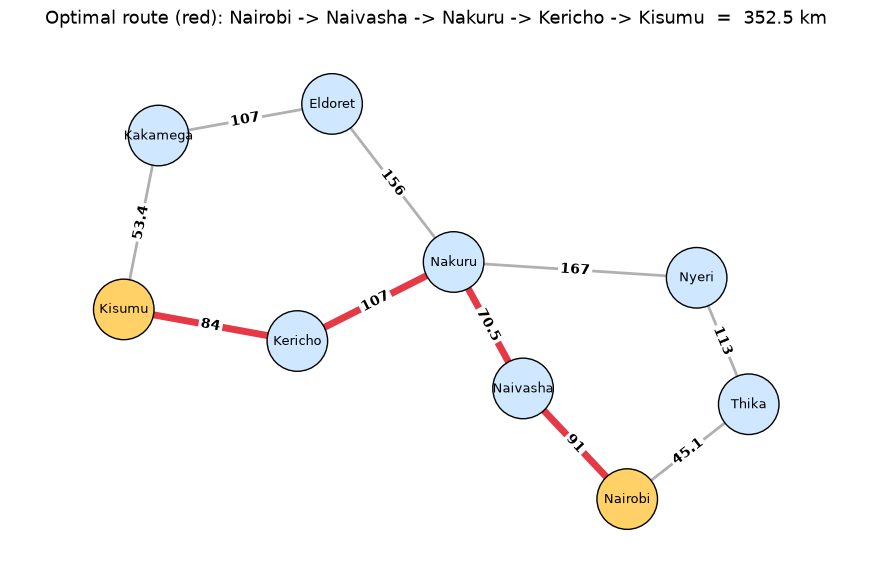

In [6]:
draw_graph(highlight_path=path, title=f"Optimal route (red): {' -> '.join(path)}  =  {cost} km")

## Step 6: Check the answer against every possible route
UCS says the best route is 352.5 km. To be sure, here we list **every** route from Nairobi to Kisumu that never visits a town twice and add up the distances by brute force. The cheapest one should match UCS.

In [7]:
routes = []
for p in nx.all_simple_paths(G, start, goal):
    total = round(sum(graph[a][b] for a, b in zip(p, p[1:])), 1)
    routes.append((total, p))
routes.sort()

check = pd.DataFrame({"Route": [" -> ".join(p) for _, p in routes], "Total (km)": [t for t, _ in routes]})
display(check.style.hide(axis="index").set_properties(**{"text-align": "left"}))

assert routes[0][1] == path and routes[0][0] == cost, "UCS result does not match brute force!"
print("\nUCS matches the cheapest route found by brute force.")

Route,Total (km)
Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu,352.500000
Nairobi -> Naivasha -> Nakuru -> Eldoret -> Kakamega -> Kisumu,477.900000
Nairobi -> Thika -> Nyeri -> Nakuru -> Kericho -> Kisumu,516.100000
Nairobi -> Thika -> Nyeri -> Nakuru -> Eldoret -> Kakamega -> Kisumu,641.500000



UCS matches the cheapest route found by brute force.


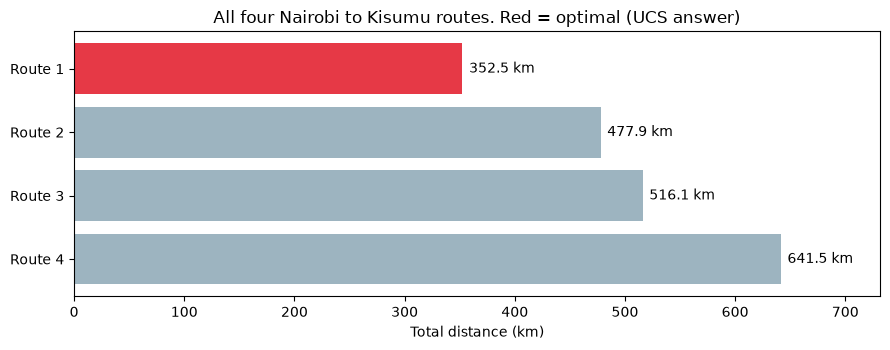

Route 1: Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu
Route 2: Nairobi -> Naivasha -> Nakuru -> Eldoret -> Kakamega -> Kisumu
Route 3: Nairobi -> Thika -> Nyeri -> Nakuru -> Kericho -> Kisumu
Route 4: Nairobi -> Thika -> Nyeri -> Nakuru -> Eldoret -> Kakamega -> Kisumu


In [8]:
labels = [f"Route {i+1}" for i in range(len(routes))]
fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.barh(labels[::-1], [t for t, _ in routes][::-1],
               color=["#e63946" if i == len(routes) - 1 else "#9db4c0" for i in range(len(routes))])
for bar, (t, p) in zip(bars, routes[::-1]):
    ax.text(t + 6, bar.get_y() + bar.get_height() / 2, f"{t} km", va="center")
ax.set_xlabel("Total distance (km)")
ax.set_title("All four Nairobi to Kisumu routes. Red = optimal (UCS answer)")
ax.set_xlim(0, max(t for t, _ in routes) + 90)
plt.tight_layout()
plt.show()
for i, (t, p) in enumerate(routes, 1):
    print(f"Route {i}: {' -> '.join(p)}")

## Step 7: How the frontier cost grew (expansion order)
Uniform Cost Search expands towns in order of cost. This chart shows the cost of each town at the moment it was expanded. It only ever goes up, which is why the first time we reach the goal we know it is the cheapest.

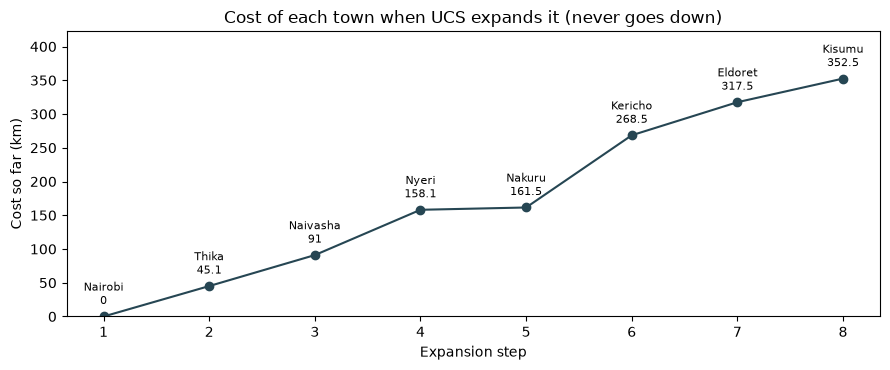

In [9]:
steps = [(r["Expand"], r["Cost so far (km)"]) for r in trace]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(1, len(steps) + 1), [c for _, c in steps], marker="o", color="#264653")
for i, (town, c) in enumerate(steps, 1):
    ax.annotate(f"{town}\n{c:g}", (i, c), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8)
ax.set_xlabel("Expansion step")
ax.set_ylabel("Cost so far (km)")
ax.set_title("Cost of each town when UCS expands it (never goes down)")
ax.set_ylim(0, max(c for _, c in steps) + 70)
ax.set_xticks(range(1, len(steps) + 1))
plt.tight_layout()
plt.show()

## Step 8: The search tree from Part 1
The same search drawn as a tree. The number beside each town is the order in which it was expanded, which matches the table above.

![Uniform-cost search tree](uniform-cost-search-tree.png)

## Conclusion
* The trailer should drive **Nairobi to Naivasha to Nakuru to Kericho to Kisumu**.
* The total cost is **352.5 km** (91.0 + 70.5 + 107 + 84.0).
* The next best routes are 477.9 km (through Eldoret and Kakamega) and 516.1 km (through Thika and Nyeri), so the winner is clear.
* This answer only holds for the towns and roads in our graph and for distance as the cost. Traffic, travel time and roadworks are not included.

## Group-work evidence

### Team photo
![Group involvement photo](group-involvement-3b.jpeg)

### GitHub links
Alvin's repository is the original. Jeremy and Travis each forked it.

| Group member | Repository | GitHub link |
|---|---|---|
| Muriuki Alvin Murithi | Original | [cypher-30/PS-Agents](https://github.com/cypher-30/PS-Agents) |
| Sebudde Jeremy Mwesigwa | Fork | [makemissionllc/PS-Agents](https://github.com/makemissionllc/PS-Agents) |
| Mutungi Travis Njenga | Fork | [Trav1s5/PS-Agents](https://github.com/Trav1s5/PS-Agents) |

The forks page of the original repository lists both forks:

![Forks page of cypher-30/PS-Agents](forks-3b.png)